# 総合課題：同時観測イベントの検証と高速化

対応する本文は [assignment.tex](../chapters/assignment.tex) である。コードセルを上から順にShift+Enterで実行する。各問の説明にある値や図と、セルの下に表示される結果を比べる。ファイルを作る問では、その直前に保存先を用意する。

## 最初に二つの時刻差を区別する

同時観測を判定するのは、異なる検出器が記録した2件の時刻の差である。Aが1000 ns、Bが1180 nsなら180 ns離れており、250 ns以内なので1組に数える。

その組を代表する時刻は2件の平均、1090 nsとする。別の組の代表時刻が2000 nsなら、組どうしの間隔は910 nsになる。次のセルではこの三つの値だけを計算する。

In [1]:
time_a = 1000
time_b = 1180
pair_difference = abs(time_b - time_a)
pair_mean = (time_a + time_b) / 2
next_pair_mean = 2000
print("1組を作る2件の時刻差 [ns]:", pair_difference)
print("この組の代表時刻 [ns]:", pair_mean)
print("2組の代表時刻の間隔 [ns]:", next_pair_mean - pair_mean)

1組を作る2件の時刻差 [ns]: 180
この組の代表時刻 [ns]: 1090.0
2組の代表時刻の間隔 [ns]: 910.0


表示は180、1090、910となる。1枚目の分布図には各組を作る2件の差、2枚目には組の代表時刻どうしの間隔を描く。

以下の実装では、日付を含む大きな時刻でもnsの差を保持するため、整数ナノ秒を使う。平均に0.5 nsが現れる場合にも対応するよう、平均の2倍に当たる和を整数で保存し、差を取ってから2で割る。

## 1．配布コードの問題を切り分ける

配布コードは学習用の比較対象として保持する。時刻差の探索そのものは同一ファイル内で行われるが、次の箇所は修正が必要となる。

- 日付が時刻に含まれず、ファイルをまたぐ同時観測を探索できない。
- 対の平均時刻を単一の浮動小数点数へ早く変換し、対を代表時刻で並べずに隣接差を計算している。
- 発生間隔を日ごとに作るため、日をまたぐ間隔が欠ける。
- 整列済み時刻で窓を超えた後も二重ループを続け、不要な比較を実行している。

以降は平均の2倍を整数で保持し、差を取った後に秒へ変換する。

まず人工入力で仕様を確定し、その後に配布データの最初の3日で66組を確認する。500日で12,033組という基準は、全期間の追加セルで照合する。

## 2．日付を含む整数ナノ秒で時刻を作る

識別子はファイル名と event_id の組として保持する。異なる検出器の対だけを採用し、検出器番号の小さい側を第1事象とする。`signed_dt_ns` は「第2事象 - 第1事象」なので正負を持つ。

ファイルを日付順に読み、各ファイル内を時刻で整列する。ファイル間でも時刻が非減少であることを検査し、重なった期間のファイルを黙って処理しない。配布データはUTCの日付を使用し、対象期間にうるう秒は含まれない。

In [2]:
import csv
import gzip
import time
from collections import deque
from datetime import date
from itertools import pairwise
from typing import NamedTuple
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np

NS_PER_SECOND = 1_000_000_000
WINDOW_NS = 250
EPOCH = date(1970, 1, 1)

class Event(NamedTuple):
    time_ns: int
    detector: int
    event_id: int
    file: str


def read_events(path):
    events = []
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line_number, line in enumerate(f, 1):
            if not line.strip() or line.lstrip().startswith("#"):
                continue
            fields = line.split()
            if len(fields) != 8:
                raise ValueError(f"{path.name}:{line_number}: 列数が8ではありません。")
            event_id, year, month, day, hhmmss, ns, detector, _signal = fields
            if len(hhmmss) != 6 or not hhmmss.isdigit():
                raise ValueError("hhmmss は6桁で指定してください。")
            hour, minute, second = int(hhmmss[:2]), int(hhmmss[2:4]), int(hhmmss[4:])
            ns = int(ns)
            if not (0 <= hour < 24 and 0 <= minute < 60 and 0 <= second < 60 and 0 <= ns < NS_PER_SECOND):
                raise ValueError("時刻の値域が不正です。")
            days = (date(int(year), int(month), int(day)) - EPOCH).days
            seconds = days * 86400 + hour * 3600 + minute * 60 + second
            events.append(Event(seconds * NS_PER_SECOND + ns, int(detector), int(event_id), path.name))
    return sorted(events)


def orient(first, second):
    return (first, second) if first.detector < second.detector else (second, first)


def find_pairs(events, window_ns=WINDOW_NS):
    """時刻が非減少の入力を時間窓で走査し、異なる検出器の全対を返す。"""
    if type(window_ns) is not int or window_ns < 0:
        raise ValueError("時間窓は0以上の整数で指定してください。")
    active = deque()
    pairs = []
    previous_time = None
    for event in events:
        if previous_time is not None and event.time_ns < previous_time:
            raise ValueError("ファイル間でも時刻を非減少順にしてください。")
        previous_time = event.time_ns
        while active and event.time_ns - active[0].time_ns > window_ns:
            active.popleft()
        for other in active:
            if other.detector != event.detector:
                pairs.append(orient(other, event))
        active.append(event)
    return pairs


def reference_pairs(events, window_ns=WINDOW_NS):
    # 時間窓の実装と独立した、全対比較による小規模入力の検証用。
    return [orient(first, second) for i, first in enumerate(events)
            for second in events[i+1:]
            if first.detector != second.detector and abs(second.time_ns-first.time_ns) <= window_ns]


def pair_key(pair):
    first, second = pair
    return (first.file, first.event_id, second.file, second.event_id)


def pair_gaps(pairs):
    twice_mean = sorted(first.time_ns + second.time_ns for first, second in pairs)
    # Python の整数で差を取り、0.5 ns の情報を残して秒へ変換する。
    return np.array([(b-a)/(2*NS_PER_SECOND) for a, b in pairwise(twice_mean)])

## 3．境界・多重対・並べ替えを検証する

時間窓の250 nsは含み、251 nsは除く。同じ検出器は除く。同時刻の異なる検出器は含む。1つの事象が2つの相手と一致すれば2対として数える。秒境界と日付境界も、整数の差では同じ条件で扱える。件数だけでなく対の集合を全対比較と照合する。

この後のセルにある `assert` は、結果が指定した条件を満たすかを確かめる命令である。違っていればエラーで止まり、条件を満たせば次へ進む。`np.testing` や `pd.testing` の確認も、配列や表の値が一致しない場合にエラーを出す。画面の数値や図と、自動の確認の両方を見る。

In [3]:
def event(t, detector, event_id, file="synthetic.gz"):
    return Event(t, detector, event_id, file)

cases = [
    [event(0, 1, 1), event(250, 2, 2)],
    [event(0, 1, 1), event(251, 2, 2)],
    [event(0, 1, 1), event(100, 1, 2)],
    [event(0, 1, 1), event(0, 2, 2)],
    [event(0, 1, 1), event(100, 2, 2), event(200, 3, 3)],
    [event(999_999_900, 1, 1), event(1_000_000_120, 2, 2)],
    [event(86400*NS_PER_SECOND-100, 1, 1, "day1.gz"),
     event(86400*NS_PER_SECOND+120, 2, 1, "day2.gz")],
    [], [event(0, 1, 1)],
]
expected_counts = [1, 0, 0, 1, 3, 1, 1, 0, 0]
for data, expected in zip(cases, expected_counts):
    found = find_pairs(sorted(data))
    assert len(found) == expected
    assert sorted(map(pair_key, found)) == sorted(map(pair_key, reference_pairs(data)))
rng = np.random.default_rng(42)
for trial in range(50):
    data = [event(int(t), int(d), i) for i, (t, d) in enumerate(
        zip(rng.integers(0, 2000, 30), rng.integers(1, 5, 30)))]
    assert sorted(map(pair_key, find_pairs(sorted(data)))) == sorted(map(pair_key, reference_pairs(data)))
# 平均時刻が探索で見つかる順とは異なる対も、代表時刻で並べ直す。
unordered_pairs = [(event(0,1,1), event(250,2,2)), (event(100,1,3), event(101,2,4))]
np.testing.assert_allclose(pair_gaps(unordered_pairs), [24.5e-9], rtol=0, atol=1e-20)
print("境界9条件とランダム入力50組を照合しました。")

境界9条件とランダム入力50組を照合しました。


## 4．最初の3日分を取り出す

ZIP の格納順は日付順とは限らないので名前で並べ替える。配布 ZIP のイベントファイルだけを読み、実習用フォルダーへコピーする。元のファイルは変更しない。

### 保存先を用意する

この後のセルではファイルを作る。次のセルを実行して、`notebooks/_outputs/13_assignment/` を用意する。表示された場所に結果が保存され、同名の実習用ファイルは再実行すると置き換わる。

Notebookは教材の `notebooks` フォルダー、または教材の一番上のフォルダーから実行する。`Path.cwd()` は現在のフォルダーを調べ、`mkdir()` は保存先を作る。

In [4]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "main.tex").is_file():
    raise FileNotFoundError("教材のフォルダーか notebooks フォルダーから実行してください。")
WORK = ROOT / "notebooks" / "_outputs" / "13_assignment"
WORK.mkdir(parents=True, exist_ok=True)
print("Python", sys.version.split()[0])
print("保存先:", WORK.relative_to(ROOT))

Python 3.12.14
保存先: notebooks/_outputs/13_assignment


In [5]:
ARCHIVE = ROOT / "events_data.zip"
SMALL = WORK / "events_data_small"
SMALL.mkdir(exist_ok=True)
with ZipFile(ARCHIVE) as archive:
    members = sorted(n for n in archive.namelist() if n.startswith("events_data/") and n.endswith(".txt.gz"))
    assert len(members) == 500
    first_three = members[:3]
    for member in first_three:
        # 展開先は検証したファイル名だけから組み立てる。
        target = SMALL / "2024" / "01" / Path(member).name
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(member))
small_paths = sorted(SMALL.rglob("events_*.txt.gz"))
assert len(small_paths) == 3
print([path.name for path in small_paths])

['events_2024_01_01.txt.gz', 'events_2024_01_02.txt.gz', 'events_2024_01_03.txt.gz']


## 5．配布コードの基準測定と正しい実装を比較する

配布コードを変更せず別プロセスで実行し、要約を保存する。二重ループのため、このセルは数十秒以上かかることがある。探索と読み込みの区間は配布コードの `analysis_sec` と比較し、プロセス起動を含む所要時間とは区別する。

同一ファイル内の同時観測件数は正しい場合もある。発生間隔や日付境界の欠落は、上の人工入力で別に検出する。

In [6]:
import subprocess

baseline_dir = WORK / "baseline"
start = time.perf_counter()
result = subprocess.run([sys.executable, str(ROOT / "slow_event_analysis.py"), str(SMALL),
                         "--outdir", str(baseline_dir)], capture_output=True, text=True, check=True, timeout=240)
baseline_wall_sec = time.perf_counter() - start
baseline = {}
for line in (baseline_dir / "summary.txt").read_text().splitlines():
    key, value = line.split()
    baseline[key] = float(value)
print("配布コード:", baseline)
print("起動・読み込み・保存・作図を含む所要時間 [s]:", baseline_wall_sec)

start = time.perf_counter()
def iter_files(paths):
    for path in paths:
        yield from read_events(path)
pairs = find_pairs(iter_files(small_paths))
analysis_sec = time.perf_counter() - start
assert len(pairs) == 66
assert len(set(map(pair_key, pairs))) == len(pairs)
with (baseline_dir / "coincidence_pairs.csv").open(newline="", encoding="utf-8") as f:
    baseline_keys = {(Path(row["file"]).name, int(row["event_id1"]),
                      Path(row["file"]).name, int(row["event_id2"])) for row in csv.DictReader(f)}
assert baseline_keys == set(map(pair_key, pairs))
print("整数時刻・時間窓による実装:", len(pairs), "組; 読み込みと探索 [s]:", analysis_sec)
print("同じ3日分の analysis_sec の比:", baseline["analysis_sec"] / analysis_sec)

配布コード: {'n_pairs_total': 66.0, 'analysis_sec': 8.294234, 'plot_sec': 0.274185, 'total_sec': 8.569017}
起動・読み込み・保存・作図を含む所要時間 [s]: 8.874799374956638
整数時刻・時間窓による実装: 66 組; 読み込みと探索 [s]: 0.07434666715562344
同じ3日分の analysis_sec の比: 111.56161153314913


## 6．対の一覧と代表時刻の間隔を保存する

対の識別には両方のファイル名を保存する。代表時刻の2倍を整数で保存すれば、半ナノ秒の違いを保持できる。発生間隔は全対を代表時刻で並べてから作り、対の数より1件少なくなる。

In [7]:
OUTPUT = WORK / "optimized"
OUTPUT.mkdir(exist_ok=True)
records = [{"file1": a.file, "event_id1": a.event_id, "detector_id1": a.detector,
            "file2": b.file, "event_id2": b.event_id, "detector_id2": b.detector,
            "signed_dt_ns": b.time_ns-a.time_ns, "twice_mean_time_ns": a.time_ns+b.time_ns}
           for a, b in pairs]
fields = ["file1", "event_id1", "detector_id1", "file2", "event_id2", "detector_id2", "signed_dt_ns", "twice_mean_time_ns"]
with (OUTPUT / "coincidence_pairs.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(records)
with (OUTPUT / "coincidence_pairs.csv").open(newline="", encoding="utf-8") as f:
    restored = list(csv.DictReader(f))
assert len(restored) == 66
assert int(restored[0]["twice_mean_time_ns"]) == records[0]["twice_mean_time_ns"]
gaps = pair_gaps(pairs)
assert len(gaps) == len(pairs)-1 and np.all(gaps >= 0)
print("対:", len(pairs), "間隔:", len(gaps), "0秒の間隔:", np.count_nonzero(gaps == 0))

対: 66 間隔: 65 0秒の間隔: 0


## 7．時間窓で選択された分布をフィットする

`|dt| <= 250 ns` の選択があるので、正規分布をそのまま当てはめると選択の影響を無視する。ここでは窓内で規格化した切断正規分布を候補とし、個々の時刻差に対する尤度を最大化する。ヒストグラムへ重ねる期待計数はビン内の確率を積分して求める。

これは候補モデルの実装例である。共有事象を持つ対は独立ではなく、偶然一致や複数の検出器の特性が混ざり得る。したがって、このフィットだけで検出器の時間分解能を断定しない。図にはフィット前後の残差も示す。

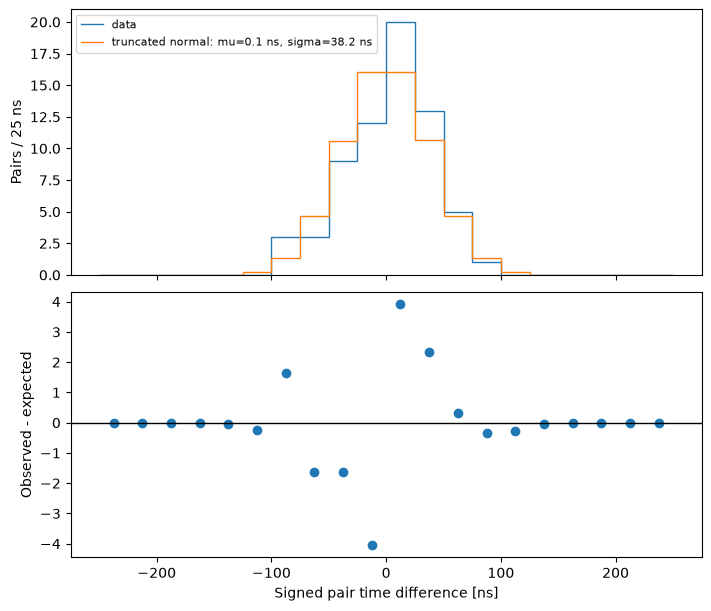

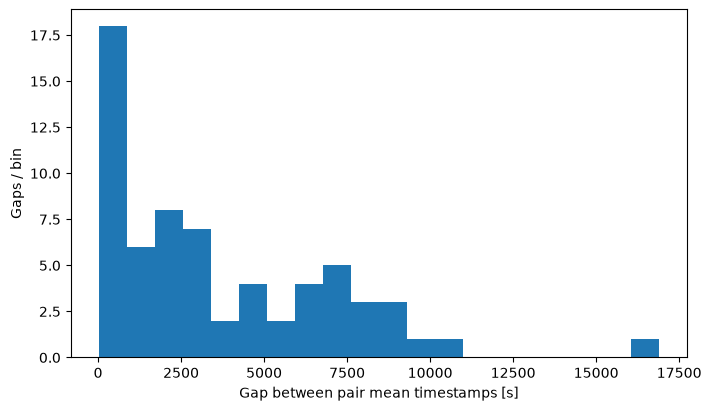

n_pairs_total = 66
analysis_sec = 0.074347
fit_and_plot_sec = 0.321186
window_ns = 250
fit_mu_ns = 0.075596
fit_sigma_ns = 38.229066
fit_range_ns = [-250, 250]
fit_model = truncated_normal
signed_dt = t(detector_id2) - t(detector_id1)



In [8]:
from scipy import stats
from scipy.optimize import minimize

signed_dt = np.array([record["signed_dt_ns"] for record in records], dtype=float)
limit = float(WINDOW_NS)
def negative_log_likelihood(parameters):
    mu, log_sigma = parameters
    sigma = np.exp(log_sigma)
    a, b = (-limit-mu)/sigma, (limit-mu)/sigma
    return -np.sum(stats.truncnorm.logpdf(signed_dt, a, b, loc=mu, scale=sigma))
fit_start = time.perf_counter()
fit_result = minimize(negative_log_likelihood,
                      [float(np.median(signed_dt)), np.log(max(float(signed_dt.std()), 1.0))],
                      bounds=[(-limit, limit), (np.log(1.0), np.log(2000.0))], method="L-BFGS-B")
assert fit_result.success, fit_result.message
mu, sigma = fit_result.x[0], np.exp(fit_result.x[1])
a, b = (-limit-mu)/sigma, (limit-mu)/sigma
edges = np.linspace(-limit, limit, 21)
counts, _ = np.histogram(signed_dt, bins=edges)
expected = len(signed_dt) * np.diff(stats.truncnorm.cdf(edges, a, b, loc=mu, scale=sigma))
assert counts.sum() == len(pairs)
np.testing.assert_allclose(expected.sum(), len(pairs), rtol=1e-10)
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(7, 6), layout="constrained")
axes[0].stairs(counts, edges, label="data")
axes[0].stairs(expected, edges, label=f"truncated normal: mu={mu:.1f} ns, sigma={sigma:.1f} ns")
axes[0].set_ylabel("Pairs / 25 ns")
axes[0].legend(fontsize=8)
centers = (edges[:-1] + edges[1:]) / 2
axes[1].plot(centers, counts-expected, "o")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="Signed pair time difference [ns]", ylabel="Observed - expected")
fig.savefig(OUTPUT / "pair_dt_hist.pdf")
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.hist(gaps, bins=20)
ax.set(xlabel="Gap between pair mean timestamps [s]", ylabel="Gaps / bin")
fig.savefig(OUTPUT / "pair_mean_gap_hist.pdf")
plt.show()
plt.close(fig)
plot_sec = time.perf_counter() - fit_start
(OUTPUT / "summary.txt").write_text(
    f"n_pairs_total = {len(pairs)}\nanalysis_sec = {analysis_sec:.6f}\n"
    f"fit_and_plot_sec = {plot_sec:.6f}\n"
    f"window_ns = {WINDOW_NS}\nfit_mu_ns = {mu:.6f}\nfit_sigma_ns = {sigma:.6f}\n"
    "fit_range_ns = [-250, 250]\nfit_model = truncated_normal\n"
    "signed_dt = t(detector_id2) - t(detector_id1)\n", encoding="utf-8")
print((OUTPUT / "summary.txt").read_text())
for name in ["coincidence_pairs.csv", "pair_dt_hist.pdf", "pair_mean_gap_hist.pdf", "summary.txt"]:
    assert (OUTPUT / name).stat().st_size > 0

## 8．全500日を検証する

`RUN_FULL = True` にすると、ZIP を一日分ずつ読み、ファイル境界でも時間窓の状態を保持したまま走査する。展開した全データをディスクへ置く必要はない。探索候補が窓に集中すると候補比較も増えるため、常に O(N) とは主張しない。時刻整列の費用と、窓内に残った候補の比較数を分けて考える。

時間窓内の候補は少数に保てるが、返す対は一覧として保持する。メモリ使用量には一日分の入力と、出力する対の数も寄与する。

In [9]:

RUN_FULL = False

def iter_archive_events(archive_path):
    with ZipFile(archive_path) as archive:
        names = sorted(n for n in archive.namelist() if n.startswith("events_data/") and n.endswith(".txt.gz"))
        for name in names:
            # 既存の読込関数を利用するため、1ファイルだけ一時的に実習先へ保存する。
            temporary = WORK / Path(name).name
            try:
                temporary.write_bytes(archive.read(name))
                yield from read_events(temporary)
            finally:
                temporary.unlink(missing_ok=True)

if RUN_FULL:
    full_start = time.perf_counter()
    full_pairs = find_pairs(iter_archive_events(ARCHIVE))
    full_elapsed = time.perf_counter() - full_start
    assert len(full_pairs) == 12033
    assert len(set(map(pair_key, full_pairs))) == len(full_pairs)
    print("全500日:", len(full_pairs), "組; 読み込み・探索 [s]:", full_elapsed)
    (OUTPUT / "full_summary.txt").write_text(f"n_pairs_total = {len(full_pairs)}\nanalysis_sec = {full_elapsed:.6f}\n", encoding="utf-8")
else:
    print("全期間の再計算は RUN_FULL = False で実行します。")

全期間の再計算は RUN_FULL = False で実行します。


## 9．レポートに結果を整理する

入力期間、時間窓、対の向き、代表時刻の定義、境界の扱いを明記する。配布コードとの比較では、同じ入力と同じ測定区間を使う。最初の3日の件数と対の一覧、人工入力の境界検査、全期間の件数は別々に記録する。図にはビン幅、単位、対象範囲、フィットモデルを添える。

さらに高速化を比較する場合は、読み込み、整列、探索、保存、フィット、描画を分けてプロファイルする。アルゴリズムと実装言語を同時に変えず、結果の一致とメモリ使用量を含めて各変更の効果を評価する。